In [ ]:
#Importing essential libraries
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
SEED=42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print('Pytorch: ', torch.__version__)
print('Device: ', device)
if device.type== 'cuda':
  print("GPU: ", torch.cuda.get_device_name(0))

Pytorch:  2.11.0+cpu
Device:  cpu


In [ ]:
#Downloading FashionMNIST dataset
#1. Convert each image into a tensor shaped [channels, height, width] and scale pixel values to [0,1]
#DataLoader converts images to batches so model can process many examples progressively

transform= transforms.ToTensor()

train_data=datasets.FashionMNIST(root='data', train=True, download=True, transform=transform)
test_data=datasets.FashionMNIST(root='data', train=False, download=True, transform=transform)

BATCH_SIZE=64
train_loader=DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)
test_loader=DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False)

classes=['T-shirt/top','Trouser','Pullover','Dress','Coat','Sandal','Shirt','Speaker','Bag','Ankle boot']
print('Training examples:', len(train_data))
print('Test examples:', len(test_data))

Training examples: 60000
Test examples: 10000


Image batch shape: torch.Size([64, 1, 28, 28])
Label batch shape: torch.Size([64])
Pixel range: 0.0 to 1.0
First label: 5 -> Sandal


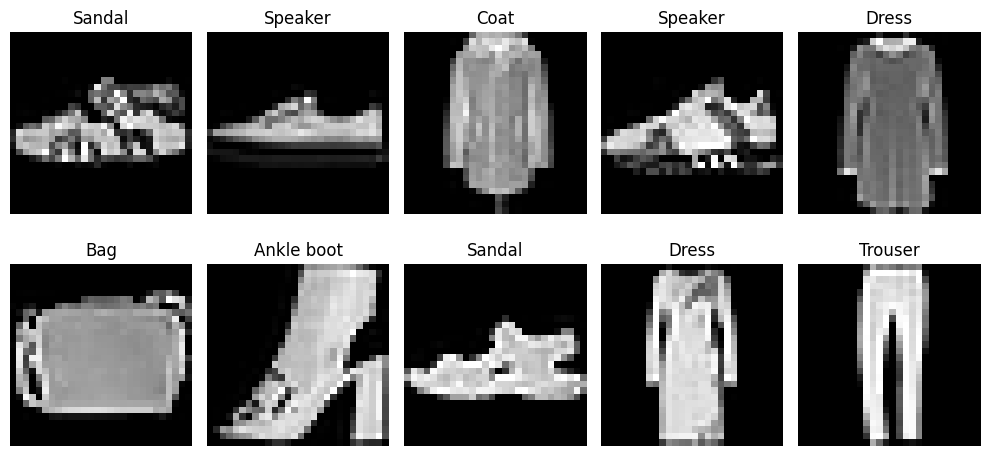

In [ ]:
images, labels = next(iter(train_loader))
print('Image batch shape:', images.shape)  # [batch, channel, height, width]
print('Label batch shape:', labels.shape)  # [batch]
print('Pixel range:', images.min().item(), 'to', images.max().item())
print('First label:', labels[0].item(), '->', classes[labels[0].item()])

fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap='gray')
    ax.set_title(classes[labels[i].item()])
    ax.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
class FashionCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 10),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

model = FashionCNN().to(device)
print(model)

FashionCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=10, bias=True)
  )
)


In [ ]:
sample = torch.randn(1, 1, 28, 28).to(device)
x = sample
print('Input:             ', tuple(x.shape))
for layer in model.features:
    x = layer(x)
    print(f'{layer.__class__.__name__:18s}', tuple(x.shape))
x = model.classifier(x)
print('Classifier output: ', tuple(x.shape), '(10 class scores)')

Input:              (1, 1, 28, 28)
Conv2d             (1, 16, 28, 28)
ReLU               (1, 16, 28, 28)
MaxPool2d          (1, 16, 14, 14)
Conv2d             (1, 32, 14, 14)
ReLU               (1, 32, 14, 14)
MaxPool2d          (1, 32, 7, 7)
Classifier output:  (1, 10) (10 class scores)


In [ ]:
#Training the model
#1. Forward pass: predict class scores
#2. Calculate loss: measure how far predictions are from labels.
#3. clear old gradients with zero_grad().
#4. Backpropagate with loss.backward() to calculate gradients.
#5. Update weights with optimizer.step().

In [ ]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
EPOCHS = 5

history = {'train_loss': [], 'train_accuracy': []}

for epoch in range(EPOCHS):
    model.train()
    total_loss, correct, total = 0.0, 0, 0

    for batch_images, batch_labels in train_loader:
        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)

        logits = model(batch_images)
        loss = loss_fn(logits, batch_labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * batch_images.size(0)
        correct += (logits.argmax(dim=1) == batch_labels).sum().item()
        total += batch_labels.size(0)

    epoch_loss = total_loss / total
    epoch_accuracy = 100 * correct / total
    history['train_loss'].append(epoch_loss)
    history['train_accuracy'].append(epoch_accuracy)
    print(f'Epoch {epoch + 1}/{EPOCHS} | loss: {epoch_loss:.4f} | train accuracy: {epoch_accuracy:.2f}%')

Epoch 1/5 | loss: 0.5262 | train accuracy: 81.11%
Epoch 2/5 | loss: 0.3506 | train accuracy: 87.56%
Epoch 3/5 | loss: 0.3104 | train accuracy: 89.04%
Epoch 4/5 | loss: 0.2858 | train accuracy: 89.84%
Epoch 5/5 | loss: 0.2686 | train accuracy: 90.38%


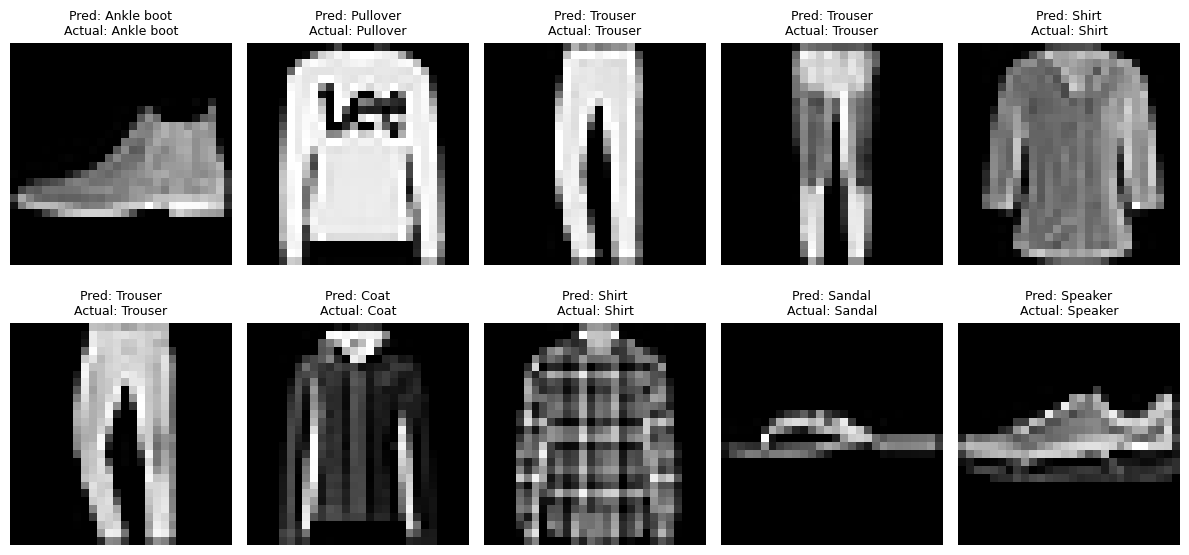

In [ ]:
images, labels = next(iter(test_loader))
model.eval()
with torch.inference_mode():
    predictions = model(images.to(device)).argmax(dim=1).cpu()

fig, axes = plt.subplots(2, 5, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    actual = classes[labels[i].item()]
    predicted = classes[predictions[i].item()]
    ax.imshow(images[i].squeeze(), cmap='gray')
    ax.set_title(f'Pred: {predicted}\nActual: {actual}', fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

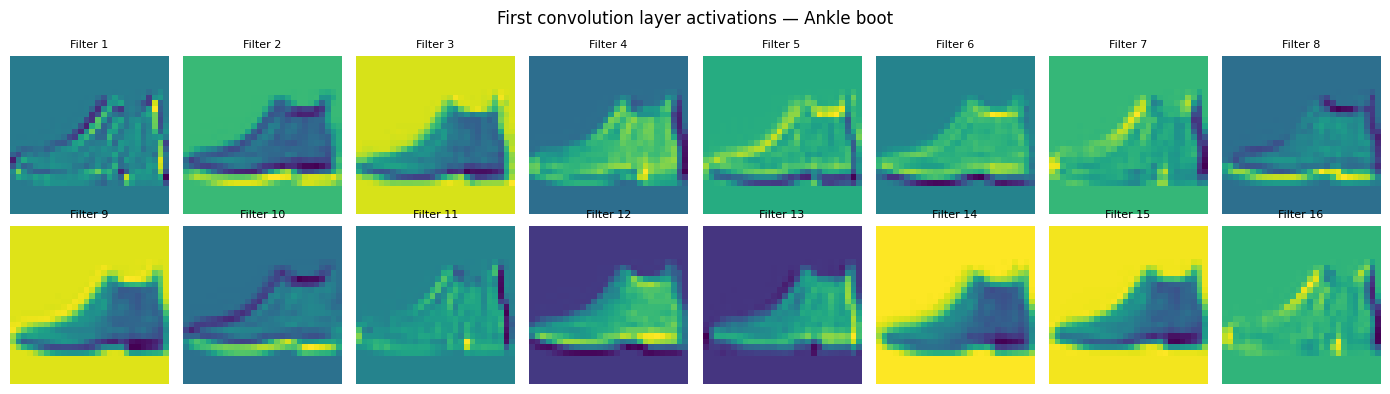

In [ ]:
model.eval()
image, label = test_data[0]
with torch.inference_mode():
    activations = model.features[0](image.unsqueeze(0).to(device)).cpu()[0]

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(activations[i], cmap='viridis')
    ax.set_title(f'Filter {i + 1}', fontsize=8)
    ax.axis('off')
plt.suptitle(f'First convolution layer activations — {classes[label]}')
plt.tight_layout()
plt.show()

In [ ]:
MODEL_PATH = 'fashion_cnn.pth'
torch.save(model.state_dict(), MODEL_PATH)
print(f'Saved model weights to {MODEL_PATH}')

# Optional: download the checkpoint to your computer from Colab.
# Uncomment if you want a local copy:
# from google.colab import files
# files.download(MODEL_PATH)

Saved model weights to fashion_cnn.pth
